In [2]:
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch:", torch.__version__, "| urządzenie:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130 | urządzenie: cuda
GPU: Tesla T4


In [3]:
x = torch.tensor([
    [1., 2., 5., 6.],
    [3., 4., 7., 8.],
    [9., 11., 2., 0.],
    [8., 6., 4., 3.]
]).view(1, 1, 4, 4)

print("Wejście 4x4:\n", x[0, 0].numpy())

print("\nMax pooling 2x2:\n",
      nn.MaxPool2d(2)(x)[0, 0].numpy())

print("\nAverage pooling 2x2:\n",
      nn.AvgPool2d(2)(x)[0, 0].numpy())

Wejście 4x4:
 [[ 1.  2.  5.  6.]
 [ 3.  4.  7.  8.]
 [ 9. 11.  2.  0.]
 [ 8.  6.  4.  3.]]

Max pooling 2x2:
 [[ 4.  8.]
 [11.  4.]]

Average pooling 2x2:
 [[2.5  6.5 ]
 [8.5  2.25]]


In [4]:
# GAP
fmap = torch.randn(1, 64, 7, 7)

gap = nn.AdaptiveAvgPool2d(1)(fmap)

print("Przed GAP:", tuple(fmap.shape))
print("Po GAP:", tuple(gap.shape))
print("Po spłaszczeniu:", tuple(gap.flatten(1).shape))

Przed GAP: (1, 64, 7, 7)
Po GAP: (1, 64, 1, 1)
Po spłaszczeniu: (1, 64)


In [5]:
class CNN(nn.Module):
    def __init__(self, n_classes=10, pool="max"):
        super().__init__()

        def block(cin, cout):
            layers = [
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU()
            ]
            if pool == "max":
                layers.append(nn.MaxPool2d(2))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(2))
            elif pool == "stride":
                layers += [
                    nn.Conv2d(cout, cout, 3,
                              stride=2, padding=1),
                    nn.BatchNorm2d(cout),
                    nn.ReLU()
                ]
            return nn.Sequential(*layers)
        self.features = nn.Sequential(
            block(1, 32),
            block(32, 64)
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        return self.head(self.features(x))

def count(m):
    return sum(p.numel() for p in m.parameters())
for p in ["max", "avg", "stride"]:
    m = CNN(pool=p)
    features = m.features(torch.randn(2, 1, 28, 28))
    out = m.head(features)
    print(
        f"pool={p:6} | parametry {count(m):7,} "
        f"| mapa {tuple(features.shape[1:])} "
        f"| wyjście {tuple(out.shape)}"
    )

pool=max    | parametry  19,658 | mapa (64, 7, 7) | wyjście (2, 10)
pool=avg    | parametry  19,658 | mapa (64, 7, 7) | wyjście (2, 10)
pool=stride | parametry  66,026 | mapa (64, 7, 7) | wyjście (2, 10)


In [6]:
# eksperyment na FashionMNIST
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])
train_ds = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=tf
)
test_ds = torchvision.datasets.FashionMNIST(
    "./data", train=False, download=True, transform=tf
)
test_dl = DataLoader(
    test_ds, batch_size=256, shuffle=False
)
train_eval_dl = DataLoader(
    train_ds, batch_size=256, shuffle=False
)

print("Liczba obrazów treningowych:", len(train_ds))
print("Liczba obrazów testowych:", len(test_ds))


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 167kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.29MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 25.1MB/s]

Liczba obrazów treningowych: 60000
Liczba obrazów testowych: 10000


In [7]:
# trening i porównanie accuracy
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item()
            total += yb.numel()
    return correct / total

def train(model, epochs=6):
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    train_accs = []
    test_accs = []
    train_dl = DataLoader(
        train_ds,
        batch_size=128,
        shuffle=True,
        generator=torch.Generator().manual_seed(0)
    )
    for e in range(epochs):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            crit(model(xb), yb).backward()
            opt.step()
        train_acc = evaluate(model, train_eval_dl)
        test_acc = evaluate(model, test_dl)
        train_accs.append(train_acc)
        test_accs.append(test_acc)

        print(
            f"Epoka {e+1}/{epochs} | "
            f"train: {train_acc*100:.2f}% | "
            f"test: {test_acc*100:.2f}%"
        )
    return train_accs, test_accs


In [8]:
# uruchomienie trzech wariantów
results = {}
for p in ["max", "avg", "stride"]:
    torch.manual_seed(0)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(0)
    m = CNN(pool=p)
    print(f"\nWariant: {p.upper()}")

    start = time.time()
    train_accs, test_accs = train(m, epochs=6)
    elapsed = time.time() - start
    results[p] = {
        "train": train_accs,
        "test": test_accs,
        "params": count(m),
        "time": elapsed
    }
    print(
        f"{p:6} | ostatnia epoka test: "
        f"{test_accs[-1]*100:.2f}% | "
        f"parametry: {count(m):,}"
    )



Wariant: MAX
Epoka 1/6 | train: 73.08% | test: 72.65%
Epoka 2/6 | train: 79.07% | test: 78.46%
Epoka 3/6 | train: 82.08% | test: 81.40%
Epoka 4/6 | train: 83.40% | test: 82.37%
Epoka 5/6 | train: 79.79% | test: 79.40%
Epoka 6/6 | train: 82.02% | test: 81.59%
max    | ostatnia epoka test: 81.59% | parametry: 19,658

Wariant: AVG
Epoka 1/6 | train: 68.43% | test: 68.17%
Epoka 2/6 | train: 75.43% | test: 75.38%
Epoka 3/6 | train: 77.65% | test: 77.02%
Epoka 4/6 | train: 80.88% | test: 80.41%
Epoka 5/6 | train: 80.52% | test: 79.91%
Epoka 6/6 | train: 81.14% | test: 80.42%
avg    | ostatnia epoka test: 80.42% | parametry: 19,658

Wariant: STRIDE
Epoka 1/6 | train: 84.45% | test: 83.45%
Epoka 2/6 | train: 88.94% | test: 87.62%
Epoka 3/6 | train: 88.80% | test: 87.27%
Epoka 4/6 | train: 90.51% | test: 88.57%
Epoka 5/6 | train: 90.44% | test: 88.55%
Epoka 6/6 | train: 91.58% | test: 89.34%
stride | ostatnia epoka test: 89.34% | parametry: 66,026


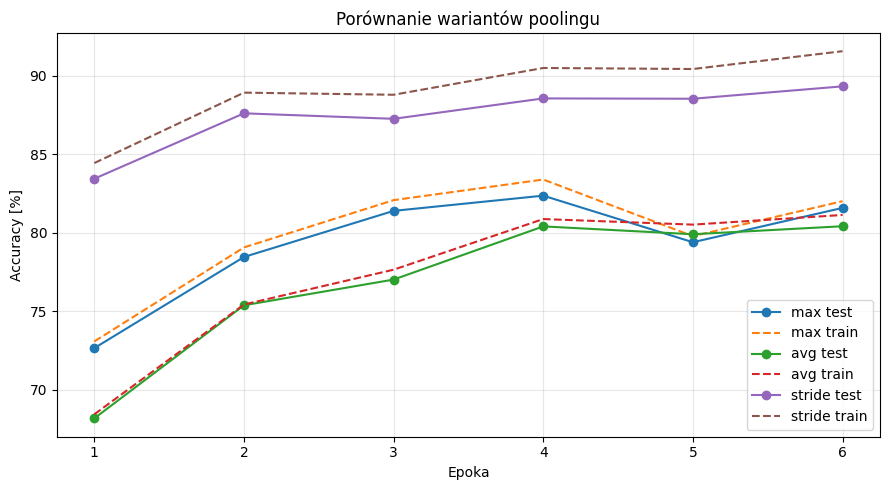

pool    |  parametry |    mapa cech |     train |      test |   przerwa
---------------------------------------------------------------------------
max     |     19,658 |   [64, 7, 7] |    82.02% |    81.59% |     0.43 pp
avg     |     19,658 |   [64, 7, 7] |    81.14% |    80.42% |     0.72 pp
stride  |     66,026 |   [64, 7, 7] |    91.58% |    89.34% |     2.24 pp


In [10]:
# krzywe i tabela
plt.figure(figsize=(9, 5))

for p, r in results.items():
    epochs = range(1, len(r["test"]) + 1)
    plt.plot(
        epochs,
        [a * 100 for a in r["test"]],
        marker="o",
        label=f"{p} test"
    )
    plt.plot(
        epochs,
        [a * 100 for a in r["train"]],
        linestyle="--",
        label=f"{p} train"
    )

plt.xlabel("Epoka")
plt.ylabel("Accuracy [%]")
plt.title("Porównanie wariantów poolingu")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    f"{'pool':7} | {'parametry':>10} | "
    f"{'mapa cech':>12} | {'train':>9} | "
    f"{'test':>9} | {'przerwa':>9}"
)
print("-" * 75)

for p, r in results.items():
    tr = r["train"][-1] * 100
    te = r["test"][-1] * 100
    gap = tr - te

    print(
        f"{p:7} | {r['params']:10,} | "
        f"{'[64, 7, 7]':>12} | "
        f"{tr:8.2f}% | {te:8.2f}% | "
        f"{gap:8.2f} pp"
    )
